# Bank Customer Churn Prediction
**Goal:**

Build a classification model based on a Multilayer Perceptron (MLP) to predict customer churn using historical data.

## PHASE 1 — Loading and Exploring the Dataset (EDA)
The goal of this phase is to understand the structure of the data, spot anomalies, and lay the groundwork for preprocessing.

### 1.1 Loading and Initial Inspection of the Dataset
Load the data with pandas and check that the dimensions (10,000 rows, 14 columns) and the data type of each column were read correctly.

In [1]:
import pandas as pd

# 1. Load the dataset (download from Kaggle and place it in the data/ folder -- see README)
file_path = 'data/Churn_Modelling.csv'
df = pd.read_csv(file_path)

# 2. Check the dimensions
print(f"Dataset dimensions: {df.shape}")
print("-" * 50)

# 3. General overview of the structure and data types
df.info()

# 4. Check that it loaded correctly by showing the first 5 rows
display(df.head())


Dimensiones del dataset: (10000, 14)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### 1.2 Missing Values and Duplicate Records Analysis
Check the integrity of the dataset by looking for missing values (NaN) and duplicate rows or customers (CustomerID), to make sure the data is good before the descriptive analysis.

In [2]:
# 1. Check for missing values
print("Missing values per column:")
print(df.isnull().sum())
print("-" * 50)

# 2. Check for duplicate rows
duplicate_rows = df.duplicated().sum()
print(f"Number of exact duplicate rows in the dataset: {duplicate_rows}")


Valores nulos por columna:
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
--------------------------------------------------
Cantidad de filas exactamente duplicadas en el dataset: 0


In [3]:
# 3. Check for duplicate customer IDs
duplicate_customers = df.duplicated(subset=['CustomerId']).sum()
print(f"Number of duplicate CustomerId values: {duplicate_customers}")


Cantidad de CustomerId duplicados: 0


### 1.3 Descriptive Statistics
Look at the main statistics (mean, standard deviation, quartiles, and extreme values) to understand how the numeric variables are distributed. Special attention is given to key variables such as age (Age), credit score (CreditScore), and account balance (Balance).

In [4]:
# 1. General statistical summary (rounded to 2 decimals)
summary = df.describe().round(2)
display(summary)

# 2. Closer look at the 'Balance' column (customers with a $0 balance)
customers_zero_balance = (df['Balance'] == 0).sum()
pct_zero_balance = (customers_zero_balance / len(df)) * 100

print("-" * 50)
print(f"Number of customers with a $0 balance: {customers_zero_balance}")
print(f"Percentage of total customers: {pct_zero_balance:.2f}%")


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,5000.50,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,2886.90,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,1.00,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,2500.75,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,5000.50,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,7500.25,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,10000.00,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


--------------------------------------------------
Cantidad de clientes con saldo $0: 3617
Porcentaje del total de clientes: 36.17%


### 1.4 Target Variable Analysis (Exited)
Check the class distribution to confirm the class imbalance, a key factor for choosing metrics (F1-score) and resampling techniques (SMOTE) later on.

Distribución absoluta de la variable objetivo (Exited):
Exited
0    7963
1    2037
Name: count, dtype: int64
--------------------------------------------------
Distribución porcentual:
Exited
0    79.63%
1    20.37%
Name: proportion, dtype: object


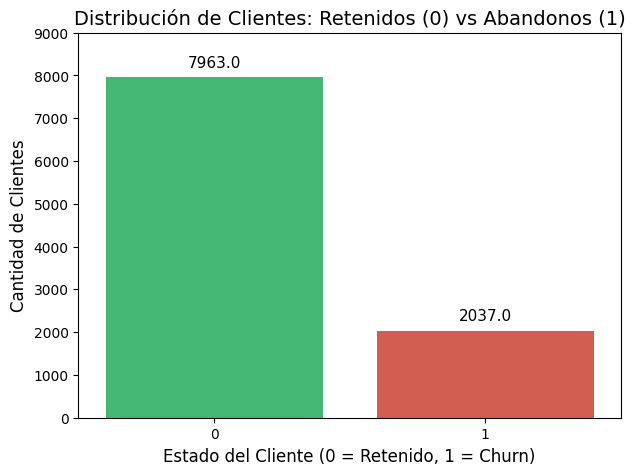

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate counts and percentages
class_counts = df['Exited'].value_counts()
class_pct = df['Exited'].value_counts(normalize=True) * 100

print("Absolute distribution of the target variable (Exited):")
print(class_counts)
print("-" * 50)
print("Percentage distribution:")
print(class_pct.round(2).astype(str) + '%')

# 2. Visualize the class imbalance
plt.figure(figsize=(7, 5))
# Use hue='Exited' and legend=False to avoid warnings in newer Seaborn versions
ax = sns.countplot(data=df, x='Exited', hue='Exited', palette=['#2ecc71', '#e74c3c'], legend=False)

plt.title('Customer Distribution: Retained (0) vs Churned (1)', fontsize=14)
plt.xlabel('Customer Status (0 = Retained, 1 = Churn)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Add data labels above the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 5), 
                textcoords='offset points')

plt.ylim(0, 9000) # Adjust the Y axis so the numbers don't get cut off
plt.show()


### 1.5 Univariate Analysis
Look at each attribute of the dataset individually to understand its behavior, splitting the study by the type of data.

#### 1.5.1 Distribution of Numeric Variables
Generate histograms to visualize the shape, skewness, and concentration of the quantitative features (such as credit score, age, and balance).

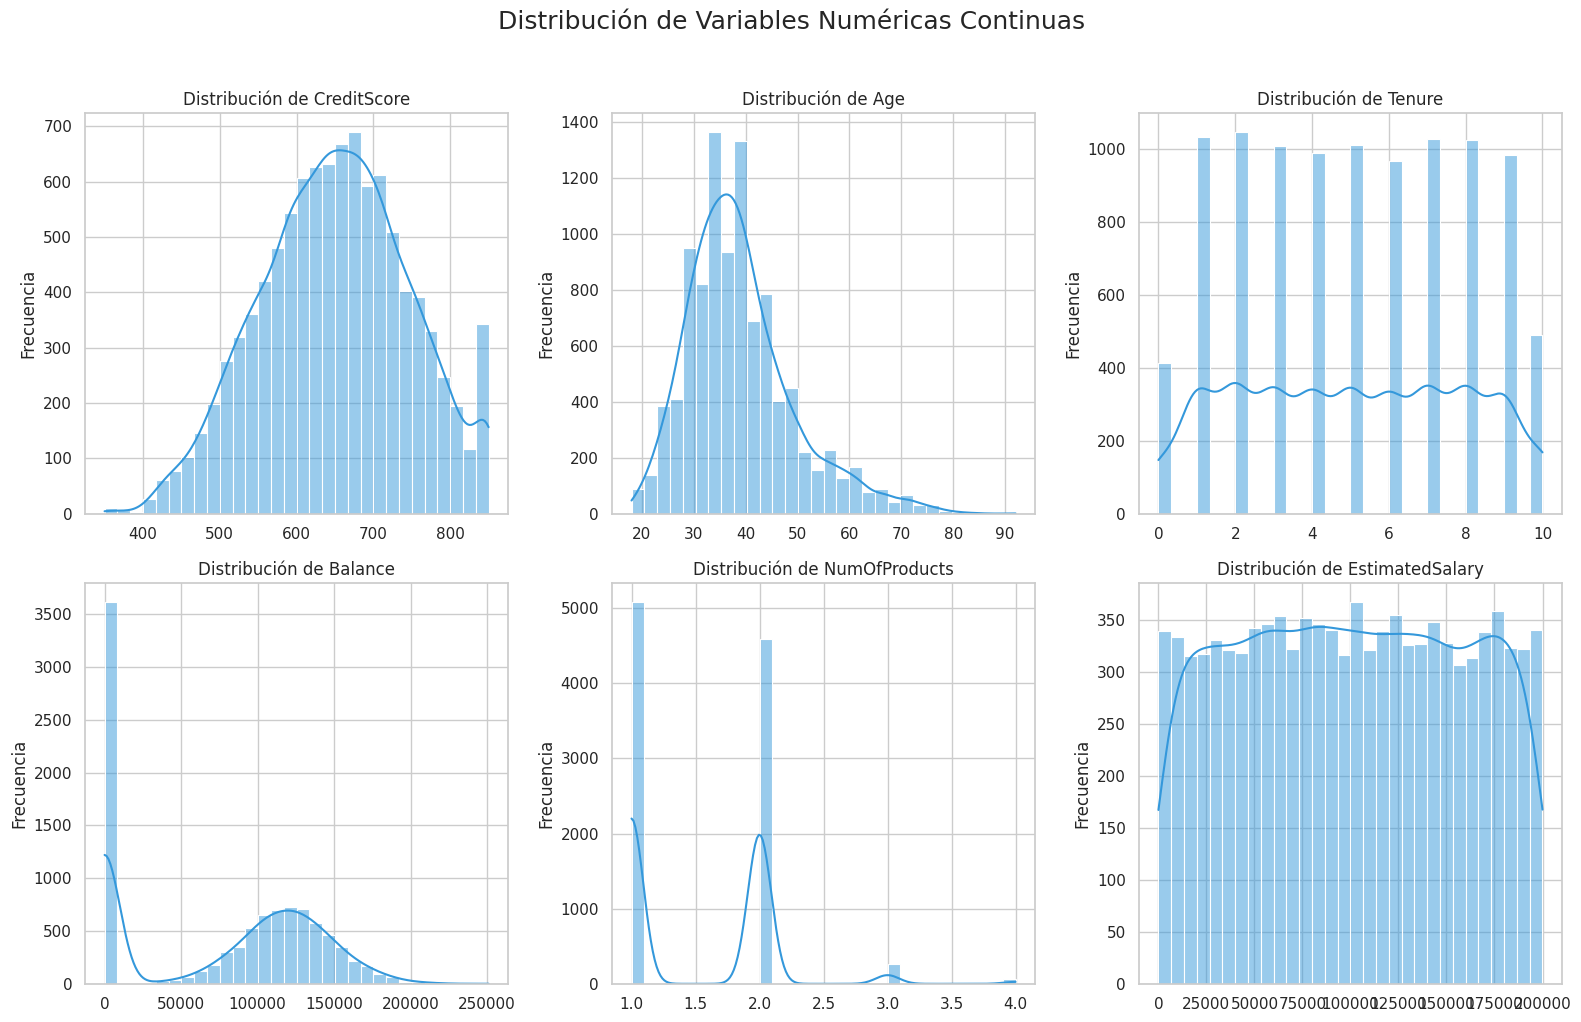

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings for cleaner plots
sns.set_theme(style="whitegrid")

# Define the numeric variables of interest
numeric_vars = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

# Create a figure with a 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribution of Continuous Numeric Variables', fontsize=18, y=1.02)

# Loop to generate each histogram with its density curve (KDE)
for i, col in enumerate(numeric_vars):
    row = i // 3
    col_pos = i % 3

    # Histogram with density curve
    sns.histplot(data=df, x=col, kde=True, ax=axes[row, col_pos], color='#3498db', bins=30)

    axes[row, col_pos].set_title(f'Distribution of {col}', fontsize=12)
    axes[row, col_pos].set_xlabel('') # Clear the X label for readability
    axes[row, col_pos].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


#### 1.5.2 Frequency of Categorical and Binary Variables
Use bar charts to look at the customer base composition based on its qualitative and boolean attributes (such as country of residence, gender, and activity status).

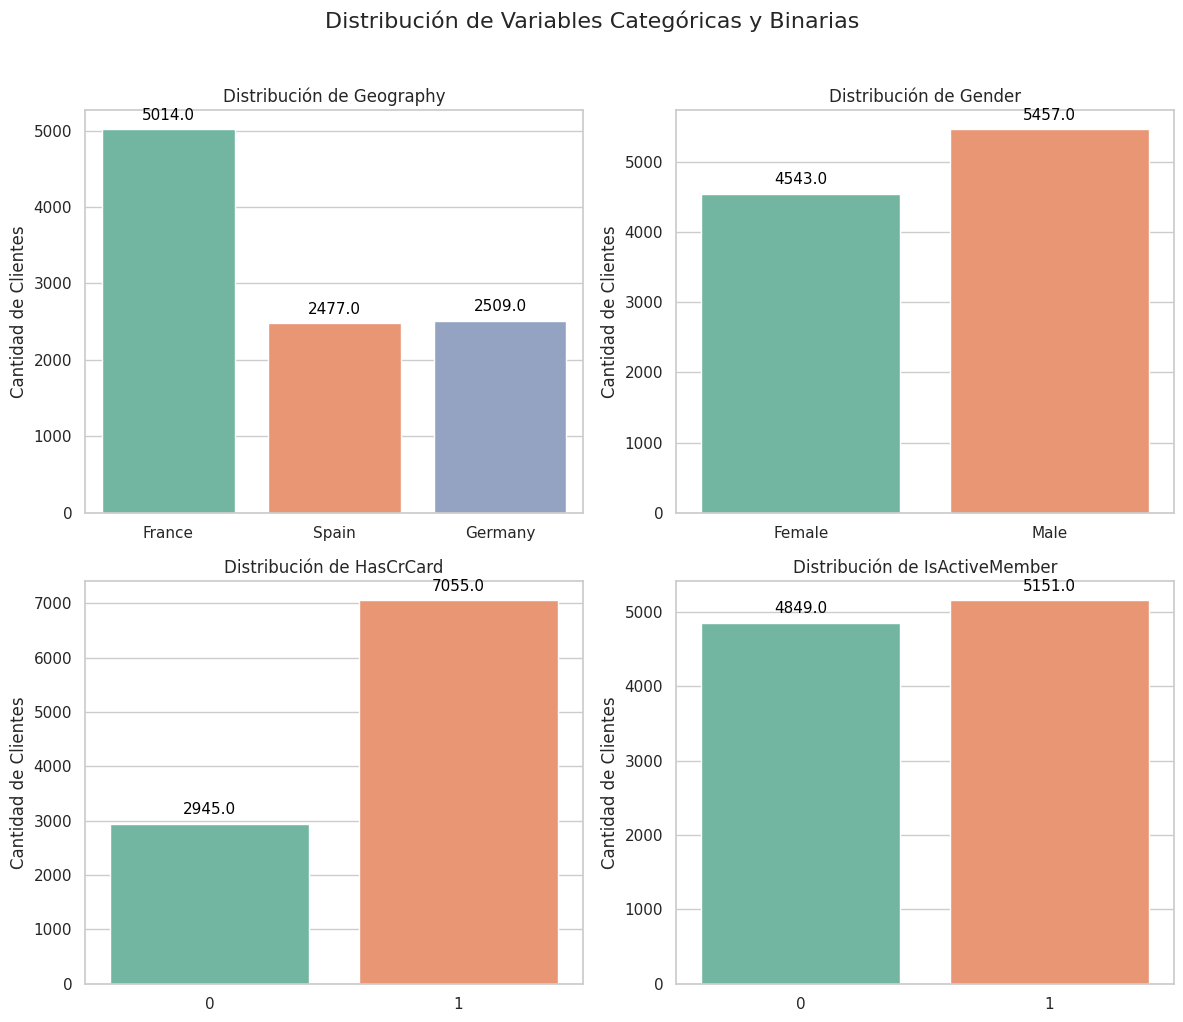

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define the categorical and binary variables
categorical_vars = ['Geography', 'Gender', 'HasCrCard', 'IsActiveMember']

# Create a figure with 2 rows and 2 columns
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Distribution of Categorical and Binary Variables', fontsize=16, y=1.02)

for i, col in enumerate(categorical_vars):
    row = i // 2
    col_pos = i % 2

    # Generate the count plot
    ax = sns.countplot(data=df, x=col, ax=axes[row, col_pos], palette='Set2', hue=col, legend=False)

    axes[row, col_pos].set_title(f'Distribution of {col}', fontsize=12)
    axes[row, col_pos].set_xlabel('')
    axes[row, col_pos].set_ylabel('Number of Customers')

    # Add data labels above each bar
    for p in ax.patches:
        ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 5),
                    textcoords='offset points')

plt.tight_layout()
plt.show()


### 1.6 Bivariate Analysis (Variables vs. Exited)
Explore the relationship between each customer feature and the target variable (churn). Proportion bar charts are used for categorical variables and boxplots for numeric variables, to visually identify the main predictors of churn.

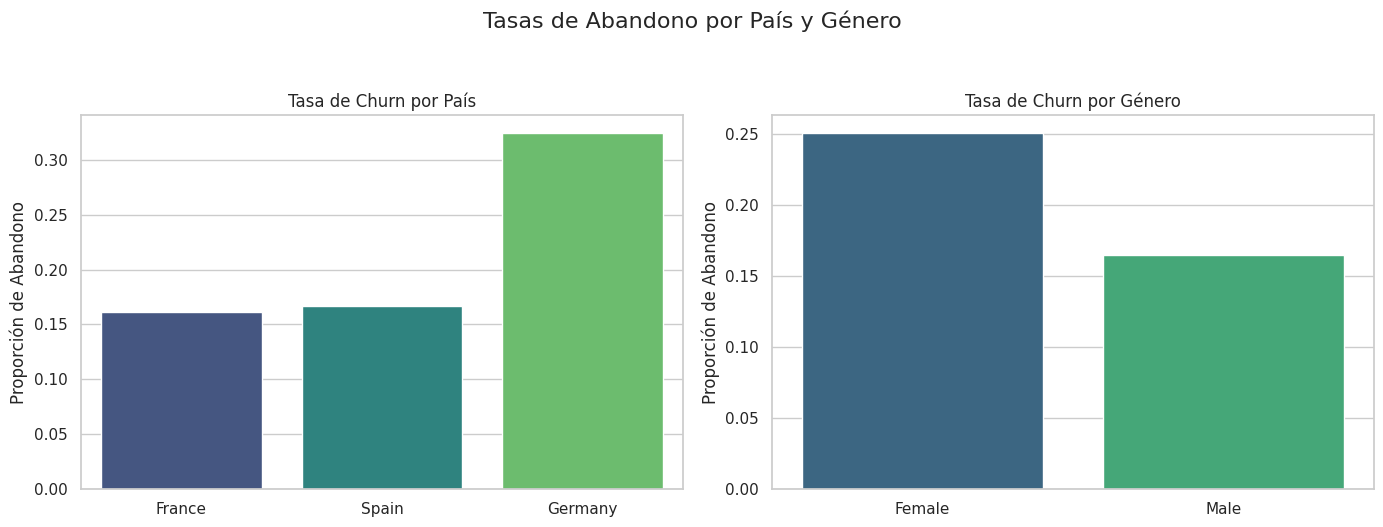

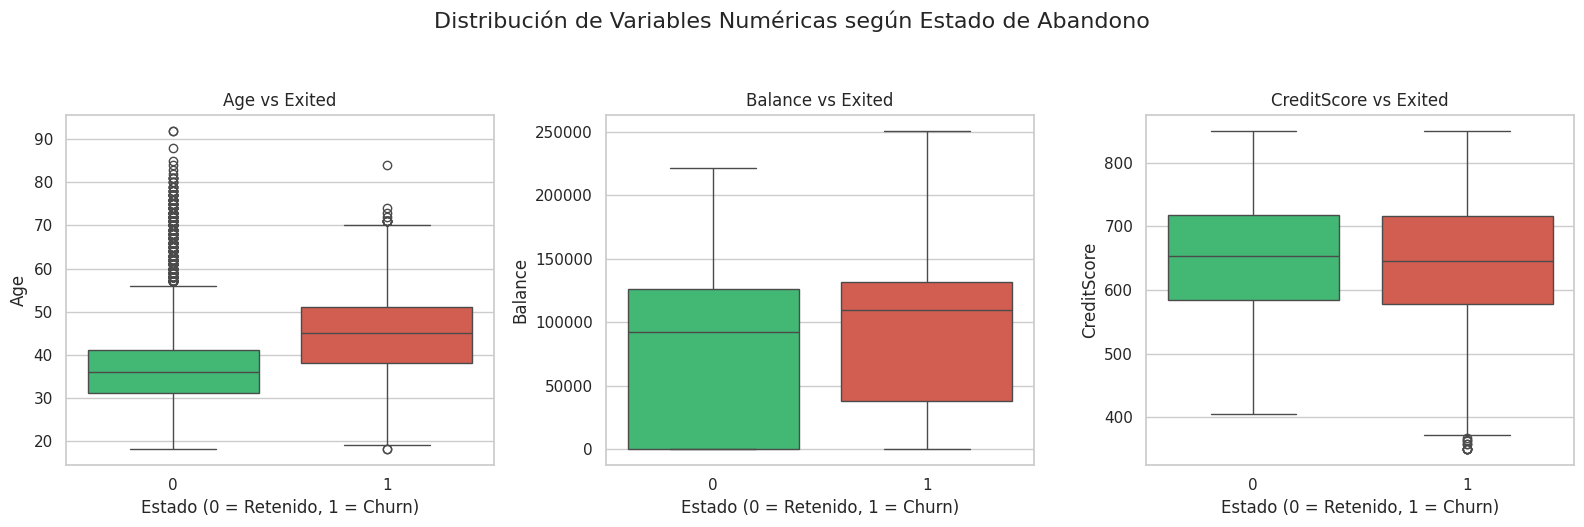

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# General settings
sns.set_theme(style="whitegrid")

# --- PART 1: Categorical Variables vs Exited ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Churn Rate by Country and Gender', fontsize=16, y=1.05)

# Churn by Geography
sns.barplot(data=df, x='Geography', y='Exited', ax=axes[0], palette='viridis', errorbar=None, hue='Geography', legend=False)
axes[0].set_title('Churn Rate by Country', fontsize=12)
axes[0].set_ylabel('Churn Proportion')
axes[0].set_xlabel('')

# Churn by Gender
sns.barplot(data=df, x='Gender', y='Exited', ax=axes[1], palette='viridis', errorbar=None, hue='Gender', legend=False)
axes[1].set_title('Churn Rate by Gender', fontsize=12)
axes[1].set_ylabel('Churn Proportion')
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

print("\n" + "="*50 + "\n")

# --- PART 2: Numeric Variables vs Exited ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Distribution of Numeric Variables by Churn Status', fontsize=16, y=1.05)

boxplot_vars = ['Age', 'Balance', 'CreditScore']

for i, col in enumerate(boxplot_vars):
    sns.boxplot(data=df, x='Exited', y=col, ax=axes[i], palette=['#2ecc71', '#e74c3c'], hue='Exited', legend=False)
    axes[i].set_title(f'{col} vs Exited', fontsize=12)
    axes[i].set_xlabel('Status (0 = Retained, 1 = Churn)')

plt.tight_layout()
plt.show()


### 1.6.1 Correlation Matrix (Heatmap)
Pearson linear correlation analysis between the numeric variables and the target variable, to identify possible multicollinearity and get an initial read on predictive relationships.

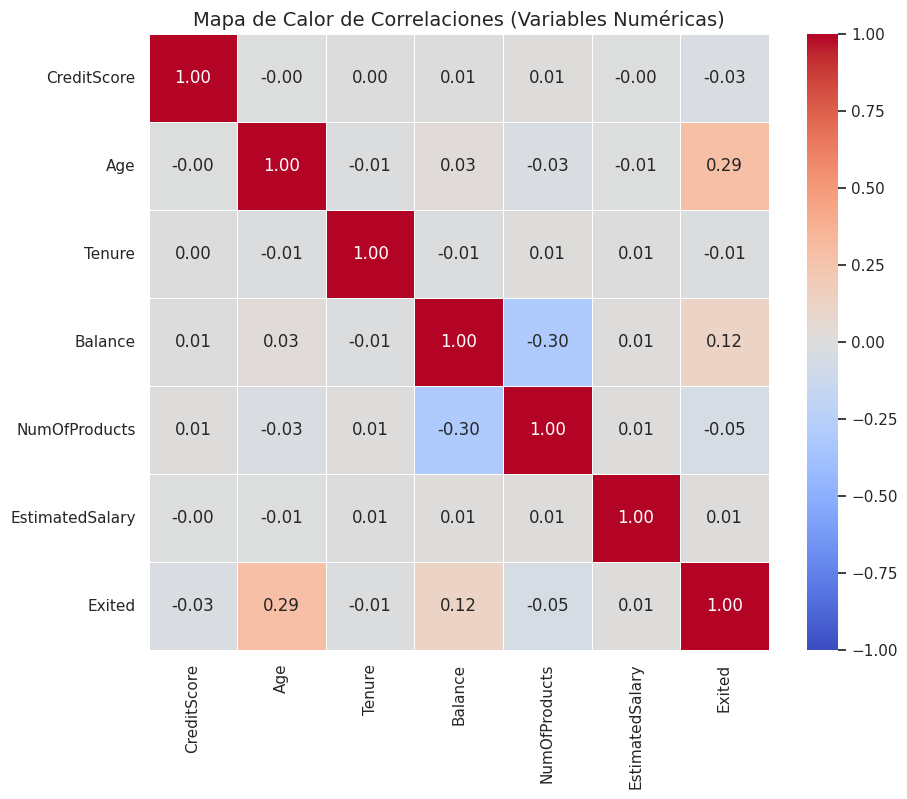

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Select only the numeric variables, including the target variable
numeric_cols = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary', 'Exited']
corr_matrix = df[numeric_cols].corr()

# 2. Set the figure size
plt.figure(figsize=(10, 8))

# 3. Generate the heatmap
# annot=True shows the numbers, cmap='coolwarm' gives intuitive colors (red positive, blue negative)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title('Correlation Heatmap (Numeric Variables)', fontsize=14)
plt.show()


### 1.7 Visual Outlier Detection
Use univariate boxplots to spot extreme values in the numeric variables. This step is key for deciding how to handle them (such as winsorization) in the preprocessing phase, so these values don't distort the neural network's weights.

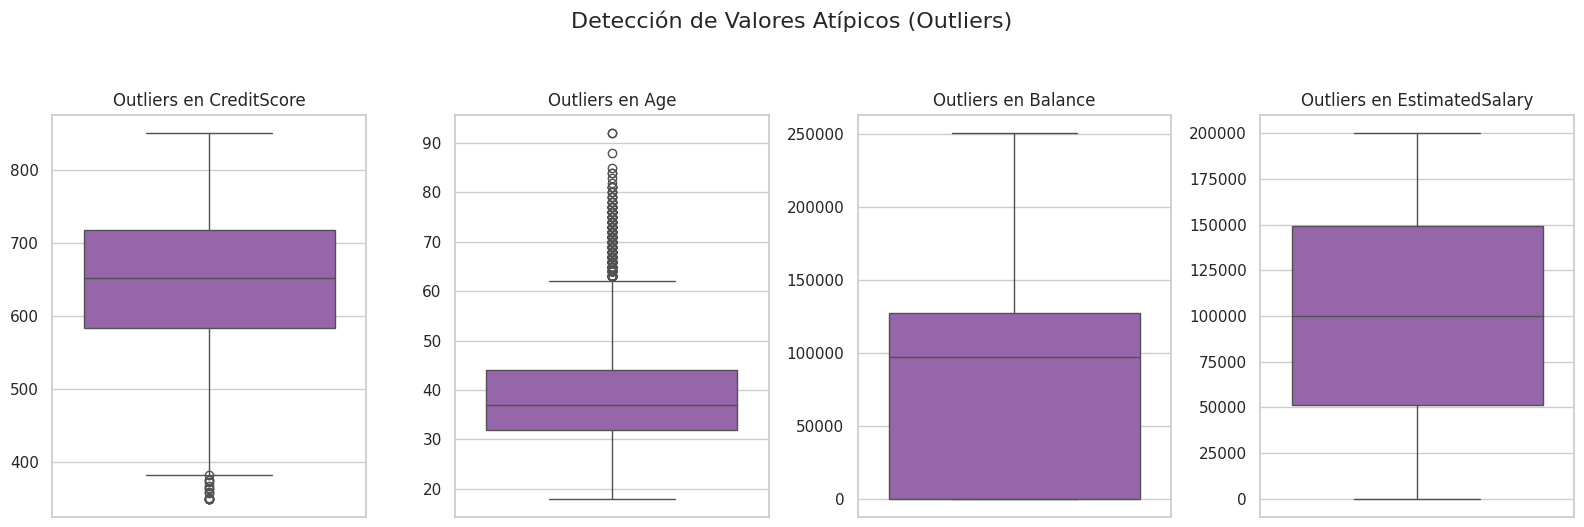

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visual settings
sns.set_theme(style="whitegrid")

# Continuous variables to evaluate
outlier_vars = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('Outlier Detection', fontsize=16, y=1.05)

for i, col in enumerate(outlier_vars):
    # Vertical boxplots for a clearer view of the extremes
    sns.boxplot(data=df, y=col, ax=axes[i], color='#9b59b6')
    axes[i].set_title(f'Outliers in {col}', fontsize=12)
    axes[i].set_ylabel('') # Hide the Y label for a cleaner look

plt.tight_layout()
plt.show()


### Conclusions for Phase 1 (Exploratory Data Analysis)
After inspecting and visually exploring the 10,000 records in the dataset, the following key findings will guide the preprocessing strategy and the design of the Multilayer Perceptron:

**1. Data Integrity:** The dataset is highly clean; it has no missing values and no duplicate customers, so no cleaning is required.

**2. Class Imbalance:** There is a significant imbalance in the target variable (~80% retained vs. ~20% churned), which makes a stratified train/test split strictly necessary and justifies using oversampling techniques later on.

**3. Churn Hotspots (Demographics):** Geographically, customers in Germany show a critical churn rate (over 30%). The churn rate is also notably higher among female customers.

**4. Financial Behavior and Age:** Age stands out as a strong visual predictor, showing that the bank is losing older customers. It's also notable that 36.17% of the customer base has a $0 balance.

**5. Justification for the Model:** The low linear correlations found between customer features and churn confirm there's no multicollinearity, and support the case for a more complex non-linear model -- like the proposed neural network -- to capture the real churn patterns.

**6. Natural Outliers:** Outliers were found in variables like age and credit score. Since these represent valid customer segments, the right approach for the next phase is to cap them (winsorization) rather than remove the records.

## PHASE 2 -- Data Preprocessing
In this phase, the raw data is transformed and cleaned to turn it into an optimal numeric format that the neural network (Multilayer Perceptron) can process, making sure there's no bias or data leakage.

### 2.1 Removing Irrelevant Columns
Drop the qualitative variables with no predictive value (RowNumber, Surname, CustomerId) to avoid algorithmic noise, after first setting aside the unique customer identifiers in a separate structure for future production use.

In [11]:
# 1. Set aside and store customer_ids for the production stage
customer_ids = df['CustomerId'].copy()

# 2. Drop the columns that don't add predictive value for the neural network
cols_to_drop = ['RowNumber', 'CustomerId', 'Surname']
df_clean = df.drop(columns=cols_to_drop)

# 3. Check the result
print(f"Original dataset dimensions: {df.shape}")
print(f"Dimensions after cleaning: {df_clean.shape}")
print("-" * 50)
print("Columns that will feed the model:")
print(df_clean.columns.tolist())


Dimensiones del dataset original: (10000, 14)
Dimensiones tras la limpieza: (10000, 11)
--------------------------------------------------
Columnas que alimentarán el modelo:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


### 2.2 Encoding Categorical Variables
Convert text variables into numeric format so the neural network can process them. Binary encoding is applied to Gender, and One-Hot Encoding to Geography, keeping all three country columns to feed the 12 input neurons of the first layer.

In [12]:
# 1. Binary encoding for 'Gender' (Female = 1, Male = 0)
# Use .map() for a direct, explicit mapping
df_clean['Gender'] = df_clean['Gender'].map({'Female': 1, 'Male': 0})

# 2. One-Hot Encoding for 'Geography'
# Use pd.get_dummies with drop_first=False to keep all 3 countries
df_clean = pd.get_dummies(df_clean, columns=['Geography'], drop_first=False)

# Convert the new boolean columns from get_dummies to integers (0 and 1)
geography_cols = ['Geography_France', 'Geography_Germany', 'Geography_Spain']
df_clean[geography_cols] = df_clean[geography_cols].astype(int)

# 3. Check the final result and the new dimensions
print(f"New dataset dimensions: {df_clean.shape}")
print("-" * 50)

# Random sample for validation
print("Preview of a random sample of 10 customers:")
display(df_clean[['Gender'] + geography_cols].sample(10))


Nuevas dimensiones del dataset: (10000, 13)
--------------------------------------------------
Vista previa de una muestra aleatoria de 10 clientes:


,Gender,Geography_France,Geography_Germany,Geography_Spain
7883,1,1,0,0
5690,1,0,0,1
9959,0,0,0,1
7081,1,1,0,0
8824,1,0,0,1
5054,0,0,0,1
5380,0,0,0,1
5974,0,1,0,0
3309,1,1,0,0
1359,0,1,0,0


### 2.3 Handling Outliers (Winsorization)
Apply winsorization (capping at the 1st and 99th percentiles) only to the numeric variables that showed outliers in the exploratory analysis (CreditScore and Age - Section 1.7). This caps the extreme values without removing any records, keeping all the information and leaving the variables that already had a tight distribution (Balance and EstimatedSalary) untouched.

In [13]:
# Columns with confirmed outliers
cols_to_winsorize = ['CreditScore', 'Age']

print("Winsorization limits applied (1st - 99th percentile):")
print("-" * 50)

for col in cols_to_winsorize:
    # Calculate the lower (1st) and upper (99th) percentiles
    lower_bound = df_clean[col].quantile(0.01)
    upper_bound = df_clean[col].quantile(0.99)

    # Cap the values
    df_clean[col] = df_clean[col].clip(lower=lower_bound, upper=upper_bound)

    # Print the limits for documentation
    print(f"{col}: Minimum set to {lower_bound:.2f} | Maximum set to {upper_bound:.2f}")

print("-" * 50)
print("Winsorization complete. No rows were removed.")


Límites de Winsorización aplicados (Percentil 1% - 99%):
--------------------------------------------------
CreditScore: Mínimo fijado en 432.00 | Máximo fijado en 850.00
Age: Mínimo fijado en 21.00 | Máximo fijado en 72.00
--------------------------------------------------
Winsorización completada. No se eliminó ninguna fila.


### 2.4 Splitting Features and Target
Separate the dependent variable `Exited` (Target, $Y$) from the rest of the customer features (Features, $X$). This sets up the data structure for supervised training of the neural network.

In [14]:
# 1. Define the target variable (Target - Y)
Y = df_clean[['Exited']]

# 2. Define the predictive variables (Features - X)
X = df_clean.drop(columns=['Exited'])

# 3. Check the dimensions
print(f"X matrix dimensions (Features): {X.shape}")
print(f"Y vector dimensions (Target): {Y.shape}")
print("-" * 50)
print("The input variables that will feed the neural network are:")
for col in X.columns:
    print(f"- {col}")


Dimensiones de la matriz X (Features): (10000, 12)
Dimensiones del vector Y (Target): (10000, 1)
--------------------------------------------------
Las variables de entrada que alimentarán la red neuronal son:
- CreditScore
- Gender
- Age
- Tenure
- Balance
- NumOfProducts
- HasCrCard
- IsActiveMember
- EstimatedSalary
- Geography_France
- Geography_Germany
- Geography_Spain


### 2.5 Train/Test Split (Stratified)
Split the data into training (80%) and test (20%) sets, following the recommendations of Racz et al. (2021). Stratified sampling on the target variable is used to make sure the original churn proportion (~20%) is preserved in both sets, ensuring a representative evaluation of the model.

In [15]:
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% test
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,      # 20% for the test set
    random_state=42,     # Seed for reproducibility
    stratify=Y           # Stratify based on the target variable
)

# Check the results
print("Dataset dimensions:")
print("-" * 50)
print(f"X_train (Training): {X_train.shape}")
print(f"Y_train (Training): {Y_train.shape}")
print(f"X_test (Test):      {X_test.shape}")
print(f"Y_test (Test):      {Y_test.shape}")
print("-" * 50)

# Check that stratification worked (should stay ~20% in both)
print("Churn proportion (Class 1):")
print(f"Full dataset: {(Y['Exited'] == 1).mean():.4f}")
print(f"Training:     {(Y_train['Exited'] == 1).mean():.4f}")
print(f"Test:         {(Y_test['Exited'] == 1).mean():.4f}")


Dimensiones de los conjuntos de datos:
--------------------------------------------------
X_train (Entrenamiento): (8000, 12)
Y_train (Entrenamiento): (8000, 1)
X_test (Prueba):         (2000, 12)
Y_test (Prueba):         (2000, 1)
--------------------------------------------------
Proporción de Churn (Clase 1):
En todo el dataset:  0.2037
En Entrenamiento:    0.2037
En Prueba:           0.2035


### 2.6 Feature Scaling
Apply `StandardScaler` to normalize the scale of the predictive variables. This step is critical for the MLP's algorithm to converge efficiently.

To prevent data leakage, `fit` (computing the mean and standard deviation) is applied only to the training data, and then used to transform both the training and test sets. This way, the model evaluates the 20% test set as if these were completely new customers.

In [16]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Initialize
scaler = StandardScaler()

# 2. Fit only on the training data (to learn the parameters) and transform it
X_train_scaled = scaler.fit_transform(X_train)

# 3. Transform the test data using the learned parameters
X_test_scaled = scaler.transform(X_test)

# 4. Convert the results back to DataFrame to keep the column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

# 5. Sanity check
print("Mean of the training variables (should be close to 0):")
display(X_train_scaled.mean().round(4).head())
print("-" * 50)
print("Standard deviation of the training variables (should be 1):")
display(X_train_scaled.std().round(4).head())


Media de las variables en entrenamiento (debería ser prácticamente 0):


CreditScore    0.0
Gender         0.0
Age            0.0
Tenure        -0.0
Balance        0.0
dtype: float64

--------------------------------------------------
Desviación estándar de las variables en entrenamiento (debería ser 1):


CreditScore    1.0001
Gender         1.0001
Age            1.0001
Tenure         1.0001
Balance        1.0001
dtype: float64

In [17]:
# Replace X_train and X_test with their scaled versions so the rest of the pipeline uses normalized data
X_train = X_train_scaled.copy()
X_test  = X_test_scaled.copy()

print("X_train and X_test updated with scaled data:")
print(f"  X_train mean: {X_train.mean().mean():.4f}")
print(f"  X_test  mean: {X_test.mean().mean():.4f}")


X_train y X_test actualizados con datos escalados:
  X_train media: 0.0000
  X_test  media: 0.0006


### Conclusions for Phase 2: Preprocessing Summary
The dataset was successfully prepared, both mathematically and structurally, to be processable and free of bias for the neural network.

* **Cleaning and Encoding (2.1 - 2.2):** Non-predictive variables were dropped, and binary encoding plus One-Hot Encoding were applied to the categorical variables. The dataset went from 14 to 13 structured columns.
* **Handling Outliers (2.3):** Winsorization (1st and 99th percentiles) was applied to `CreditScore` (limits: 432 - 850) and `Age` (limits: 21 - 72) to cap extreme values while keeping all 10,000 original records intact.
* **Stratified Split (2.4 - 2.5):** The 12 input variables (X) were separated from the target variable (Y). The data was split into 80% training (8,000 records) and 20% test (2,000 records), keeping the original churn proportion of **20.37%** exactly in both sets.
* **Feature Scaling (2.6):** `StandardScaler` (fit only on the training set) was applied to bring the continuous variables to a uniform scale (mean of 0, standard deviation of 1), which is required for the neural network's algorithm to converge.

## PHASE 3 -- Class Imbalance Analysis and Handling
This phase addresses the dataset's inherent class imbalance (~20% churn vs. ~80% retention). A model trained on imbalanced data tends to ignore the minority class, resulting in low Recall (failing to detect customers who actually leave). To address this, synthetic resampling techniques and loss function adjustments will be applied, improving the model's ability to predict the event of interest.

### 3.1 Diagnosing the Imbalance in Y_train





Distribución de Clases en el Conjunto de Entrenamiento (Y_train):
------------------------------------------------------------
Clase 0 [Retenido]: 6370 (79.62%)
Clase 1 [Abandono]: 1630 (20.38%)
------------------------------------------------------------


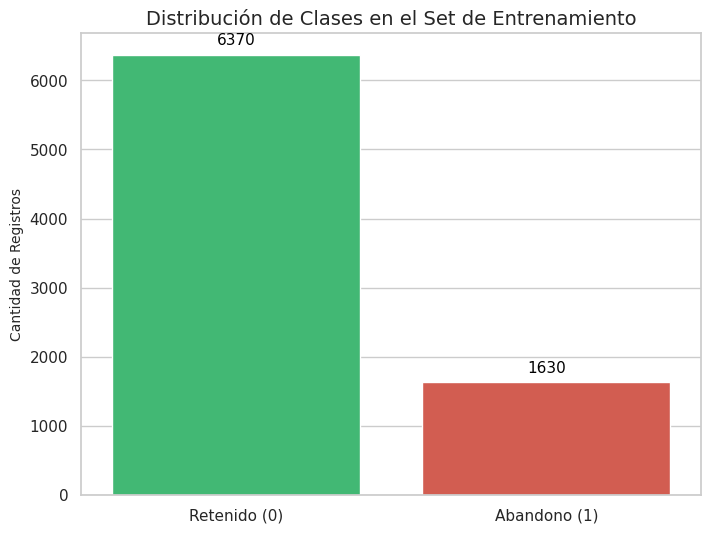

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract the 'Exited' column as a series to count values
y_series = Y_train['Exited']

# 2. Calculate absolute and relative frequencies
class_counts = y_series.value_counts().sort_index()
percentages = (y_series.value_counts(normalize=True) * 100).sort_index()

# 3. Show the results
print("Class Distribution in the Training Set (Y_train):")
print("-" * 60)
for class_, count in class_counts.items():
    status = "Retained" if class_ == 0 else "Churned"
    print(f"Class {class_} [{status}]: {count} ({percentages[class_]:.2f}%)")
print("-" * 60)

# 4. Plot
plt.figure(figsize=(8, 6))

# Explicitly use lists for the X and Y axes
ax = sns.barplot(
    x=['Retained (0)', 'Churned (1)'],
    y=class_counts.values,
    palette=['#2ecc71', '#e74c3c'],
    hue=['Retained (0)', 'Churned (1)'],
    legend=False
)

plt.title('Class Distribution in the Training Set', fontsize=14)
plt.ylabel('Number of Records', fontsize=10)

# Data labels above the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11, color='black', xytext=(0, 5),
                textcoords='offset points')

plt.show()


### 3.2 Applying SMOTE (Synthetic Minority Over-sampling Technique)
Following the recommendations of Tekouabou et al. (2022) and Suguna et al. (2025), SMOTE is applied to balance the classes. Unlike simply duplicating rows, SMOTE creates new synthetic examples by mathematically interpolating between existing customers of the minority class (Churn).

**Key note:** This transformation is applied only to the training set (`X_train_scaled`, `Y_train`). The test set stays untouched, to ensure a valid evaluation on real data.

In [19]:
from imblearn.over_sampling import SMOTE
import pandas as pd

# 2. Configure SMOTE with a seed for reproducibility
smote = SMOTE(sampling_strategy=0.5, random_state=42, k_neighbors=5)

# 3. Apply SMOTE only to the training data (using X_train_scaled since the data is already scaled from step 2.6)

X_train_smote, Y_train_smote = smote.fit_resample(X_train_scaled, Y_train)

# 4. Check the new class balance
print("Class Distribution AFTER SMOTE:")
print("-" * 50)
counts_after = Y_train_smote['Exited'].value_counts().sort_index()
pct_after = (Y_train_smote['Exited'].value_counts(normalize=True) * 100).sort_index()

for class_, count in counts_after.items():
    status = "Retained (0)" if class_ == 0 else "Churned (1)"
    print(f"Class {class_} [{status}]: {count} samples ({pct_after[class_]:.2f}%)")

print("-" * 50)
print(f"Final dimensions of X_train_smote: {X_train_smote.shape}")


Distribución de Clases DESPUÉS de SMOTE:
--------------------------------------------------
Clase 0 [Retenido (0)]: 6370 muestras (66.67%)
Clase 1 [Abandono (1)]: 3185 muestras (33.33%)
--------------------------------------------------
Dimensiones finales de X_train_smote: (9555, 12)


In [20]:
import numpy as np

# Convert Y to NumPy
Y_train_smote = np.array(Y_train_smote).astype('float32').ravel()
Y_test = np.array(Y_test).astype('float32').ravel()

print("Y conversion complete:")
print(f"  Y_train_smote -- shape: {Y_train_smote.shape} | dtype: {Y_train_smote.dtype} | unique values: {np.unique(Y_train_smote)}")
print(f"  Y_test        -- shape: {Y_test.shape} | dtype: {Y_test.dtype} | unique values: {np.unique(Y_test)}")

# Convert X to NumPy
X_train_smote = np.array(X_train_smote).astype('float32')
X_test = np.array(X_test).astype('float32')

print("X conversion complete:")
print(f"  X_train_smote -- shape: {X_train_smote.shape} | dtype: {X_train_smote.dtype}")
print(f"  X_test        -- shape: {X_test.shape} | dtype: {X_test.dtype}")

# Shuffle X_train_smote so validation_split doesn't end up with only synthetic SMOTE samples
from sklearn.utils import shuffle

X_train_smote, Y_train_smote = shuffle(
    X_train_smote,
    Y_train_smote,
    random_state=42
)

print("Shuffle complete:")
print(f"  X_train_smote shape: {X_train_smote.shape}")
print(f"  Y_train_smote shape: {Y_train_smote.shape}")

# Check that the balance was preserved
from collections import Counter
counts = Counter(Y_train_smote)
print(f"  Class 0: {counts[0.0]} | Class 1: {counts[1.0]}")


Conversión de Y completada:
  Y_train_smote — shape: (9555,) | dtype: float32 | únicos: [0. 1.]
  Y_test        — shape: (2000,) | dtype: float32 | únicos: [0. 1.]
Conversión de X completada:
  X_train_smote — shape: (9555, 12) | dtype: float32
  X_test        — shape: (2000, 12) | dtype: float32
Mezcla completada:
  X_train_smote shape: (9555, 12)
  Y_train_smote shape: (9555,)
  Clase 0: 6370 | Clase 1: 3185


After running SMOTE, the skewed training set was transformed into a balanced, robust dataset for deep learning.

* **Starting Point:** The ratio was about 4:1 (roughly 80% retained vs. 20% churned), which was a significant risk.
* **Result After SMOTE:** The training set (`X_train_smote`) now has **approximately 9,555 records**, with a **67% retained / 33% churned** split (sampling_strategy=0.5).
* **Integrity:** The test set (`X_test`) was kept fully intact and outside the resampling process, to ensure the final model evaluation reflects real-world conditions.

With this balance, the model now has a more representative proportion of both classes to learn both loyalty and churn patterns, maximizing the **Recall** potential of the upcoming neural network.

## Phase 4 -- MLP Design and Construction

### 4.1 -- Defining the MLP's Base Architecture

A deeper architecture is implemented with the following specs:
* **Hidden Layers:** Three dense layers (64, 32, and 16 neurons) with **ReLU** activation.
* **Regularization:** **Dropout (0.3)** layers after each hidden layer to randomly switch off neurons during training.
* **Output:** 1 neuron with **Sigmoid** to get the churn probability.

In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

# Set a seed for reproducibility
tf.random.set_seed(42)

# Build the model

model = keras.Sequential([

    # Input layer
    layers.Input(shape=(12,)),

    # Hidden layer 1
    layers.Dense(64, activation='relu', name='hidden_layer_1'),
    layers.Dropout(0.3, name='dropout_1'),

    # Hidden layer 2
    layers.Dense(32, activation='relu', name='hidden_layer_2'),
    layers.Dropout(0.3, name='dropout_2'),

    # Hidden layer 3
    layers.Dense(16, activation='relu', name='hidden_layer_3'),
    layers.Dropout(0.3, name='dropout_3'),

    # Output layer -- 1 Sigmoid neuron for binary classification
    # Note: this corrects the original proposal, which suggested Softmax with 2 neurons
    layers.Dense(1, activation='sigmoid', name='output_layer')

])
model.summary()


2026-03-17 14:40:31.043210: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773758431.276341      17 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773758431.348722      17 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773758431.931538      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773758431.931625      17 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773758431.931630      17 computation_placer.cc:177] computation placer alr

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_3 (Dense)           │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

### 4.2 - Compiling the Model

In this section we tell the model how it's going to learn:

which algorithm it will use to update its weights (optimizer), which function it will use to measure how wrong it is (loss function), and which metrics it will track during training.

In [22]:
from tensorflow.keras.optimizers import Adam

# Adam optimizer with an initial learning rate of 0.001
model.compile(

optimizer=Adam(learning_rate=0.001),

# Loss function
loss='binary_crossentropy',

# Metrics to display at each epoch during training

metrics=[
        'accuracy',
 ])

# Confirmation
print("Model compiled successfully.")
print(f"  Optimizer : Adam (lr=0.001)")
print(f"  Loss      : binary_crossentropy")
print(f"  Metrics   : accuracy (AUC-ROC will be calculated later)")


Modelo compilado exitosamente.
  Optimizador : Adam (lr=0.001)
  Perdida     : binary_crossentropy
  Metricas    : accuracy, (AUC-ROC se calculara mas adelante


### 4.3 -- Initial Hyperparameter Configuration

In this section we define the starting values for the hyperparameters that control how and how much the model trains. These aren't final values -- they'll be tuned in *Phase 5* -- but they need to be reasonable enough for the first training run to be informative and not fail.

In [23]:
# Hyperparameter definitions

# Maximum number of training epochs
# EarlyStopping (4.4) will stop training earlier if
# the model stops improving -- this value is just the upper limit
EPOCHS = 200

# Number of samples processed before updating the weights
# 32 is the standard value: a balance between speed and
# gradient stability
BATCH_SIZE = 32

# Fraction of the training set used for internal validation
# during training -- this is NOT X_test, it's a temporary
# split of X_train_smote used to monitor overfitting
VALIDATION_SPLIT = 0.2

# Confirm the configuration


print("Initial hyperparameters configured:")
print(f"  Max epochs       : {EPOCHS}")
print(f"  Batch size       : {BATCH_SIZE}")
print(f"  Validation split : {VALIDATION_SPLIT*100:.0f}% of the training set")
print()
print("Training set breakdown during training:")
train_size = len(X_train_smote)
val_size   = int(train_size * VALIDATION_SPLIT)
effective_train_size  = train_size - val_size
print(f"  Total X_train_smote : {train_size} samples")
print(f"  Used for training   : {effective_train_size} samples")
print(f"  Used for validation : {val_size} samples")


Hiperparámetros iniciales configurados:
  Épocas máximas   : 200
  Batch size       : 32
  Validation split : 20% del training set

Distribución del training set durante entrenamiento:
  Total X_train_smote : 9555 muestras
  Usado para entrenar : 7644 muestras
  Usado para validar  : 1911 muestras


### 4.4 -- Training Callbacks

In this section we configure the *automatic training control* mechanisms. Callbacks are functions that Keras runs at the end of each epoch to monitor progress and make decisions: stop training, save the best model, or adjust the learning rate -- all without manual intervention.

In [24]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Callback 1: EarlyStopping
# Stops training if val_loss doesn't improve after 'patience' consecutive epochs.
# Automatically restores the weights from the best epoch found.

early_stopping = EarlyStopping(
    monitor='val_loss',         # Metric to monitor
    patience=10,                # Epochs to wait without improvement
    restore_best_weights=True,  # Restore weights from the best epoch
    verbose=1
)

# Callback 2: ModelCheckpoint
# Saves the model every time val_loss improves

checkpoint = ModelCheckpoint(
    filepath='best_model_mlp.keras',  # Save file
    monitor='val_loss',
    save_best_only=True,    # Only save if it's the best so far
    verbose=1
)

# Callback 3: ReduceLROnPlateau
# Halves the learning rate if val_loss doesn't improve over 5 consecutive epochs
# Helps the model get unstuck from a learning plateau without manual intervention

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,       # Multiplies the current lr by 0.5
    patience=5,       # Epochs to wait before reducing
    min_lr=1e-6,      # Minimum allowed learning rate
    verbose=1
)

callbacks = [early_stopping, checkpoint, reduce_lr]

print("Callbacks configured:")
print("  - EarlyStopping      -- patience: 10 epochs | monitor: val_loss")
print("  - ModelCheckpoint    -- saves to: best_model_mlp.keras")
print("  - ReduceLROnPlateau  -- factor: 0.5 | patience: 5 epochs")


Callbacks configurados:
  ✓ EarlyStopping      — paciencia: 10 epocas | monitor: val_loss
  ✓ ModelCheckpoint    — guarda en: mejor_modelo_mlp.keras
  ✓ ReduceLROnPlateau  — factor: 0.5 | paciencia: 5 epocas


### 4.5 Checking the Regularization

Check that regularization is correctly integrated into the model.

In [25]:
print("Model Regularization Configuration:")
print("=" * 50)

for layer in model.layers:
    if 'dropout' in layer.name:
        print(f"  - {layer.name}: rate = {layer.rate} ({layer.rate*100:.0f}% of neurons dropped per epoch)")
    elif 'dense' in layer.name:
        print(f"  . {layer.name}: {layer.output.shape[-1]} neurons -- no additional regularization")

print()
print("Regularization strategy applied:")
print("  - Dropout 0.3 after each hidden layer")
print("  - ReduceLROnPlateau acts as implicit regularization")
print("  - EarlyStopping prevents overfitting from too many epochs")


Configuración de Regularización del Modelo:
  ✓ dropout_1: tasa = 0.3 (30% de neuronas apagadas por epoca)
  ✓ dropout_2: tasa = 0.3 (30% de neuronas apagadas por epoca)
  ✓ dropout_3: tasa = 0.3 (30% de neuronas apagadas por epoca)

Estrategia de regularizacion aplicada:
  - Dropout 0.3 después de cada capa oculta
  - ReduceLROnPlateau actúa como regularizacion implícita
  - EarlyStopping previene overfitting por exceso de epocas


## Phase 5 -- Training and Hyperparameter Tuning

In this phase, the MLP model built in Phase 4 is trained and its
performance is systematically optimized.

The process follows four stages:
1. **Initial training** with the base architecture to get
   baseline results.
2. **Visual diagnosis** using learning curves to detect
   overfitting or underfitting.
3. **Experimentation** with different architectures and hyperparameters
   to improve the base model.
4. **Cross-validation** (K-Fold, k=5) to confirm that the best
   model generalizes robustly.

The main criterion for choosing between models is **AUC-ROC**
on the validation set, supported by Li (2024) as the most
consistent metric for binary classification.

All training is done exclusively on `X_train_smote`.

### 5.1 Initial Training
Train the base architecture defined in Phase 4 using `X_train_smote`. 

In [26]:
import time

print("Starting MLP model training...")
print("=" * 50)
print(f"  Training samples    : {len(X_train_smote)}")
print(f"  Max epochs          : {EPOCHS}")
print(f"  Batch size          : {BATCH_SIZE}")
print(f"  Internal validation : {VALIDATION_SPLIT*100:.0f}%")
print("=" * 50)

start_time = time.time()

history = model.fit(
    X_train_smote,               # Training features (post-SMOTE)
    Y_train_smote,               # Training target (post-SMOTE)
    epochs=EPOCHS,               # Max number of epochs
    batch_size=BATCH_SIZE,       # Samples per weight update
    validation_split=VALIDATION_SPLIT,  # 20% internal monitoring split
    callbacks=callbacks,         # EarlyStopping + Checkpoint + ReduceLR
    verbose=1                    # Show progress per epoch
)

end_time = time.time()


# Post-training summary

epochs_run    = len(history.history['loss'])
best_val_loss = min(history.history['val_loss'])
best_val_acc  = max(history.history['val_accuracy'])
best_epoch    = history.history['val_loss'].index(best_val_loss) + 1

print("\n" + "=" * 50)
print("TRAINING SUMMARY:")
print("=" * 50)
print(f"  Epochs run        : {epochs_run} / {EPOCHS}")
print(f"  Training time     : {end_time - start_time:.1f} seconds")
print(f"  Best epoch        : {best_epoch}")
print(f"  Best val_loss     : {best_val_loss:.4f}")
print(f"  Best val_accuracy : {best_val_acc:.4f}")
print()
if epochs_run < EPOCHS:
    print("  - EarlyStopping triggered -- weights restored to the best epoch.")
else:
    print(f"  ! The model trained all {EPOCHS} epochs.")
    print("    Consider increasing EPOCHS or reviewing the configuration.")


Iniciando entrenamiento del modelo MLP...
  Muestras de entrenamiento : 9555
  Épocas máximas            : 200
  Batch size                : 32
  Validación interna        : 20%
Epoch 1/200
229/239 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6266 - loss: 0.6415
Epoch 1: val_loss improved from inf to 0.52726, saving model to mejor_modelo_mlp.keras
239/239 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6288 - loss: 0.6396 - val_accuracy: 0.7473 - val_loss: 0.5273 - learning_rate: 0.0010
Epoch 2/200
229/239 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7381 - loss: 0.5466
Epoch 2: val_loss improved from 0.52726 to 0.49124, saving model to mejor_modelo_mlp.keras
239/239 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7380 - loss: 0.5462 - val_accuracy: 0.7776 - val_loss: 0.4912 - learning_rate: 0.0010
Epoch 3/200
222/239 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7543 - loss: 0.5101
Epoch 3: val_loss improved from 0.49124 to 0.46665, saving model to mejor_modelo_mlp.keras
239/239 ━━

In [27]:
print("Epoch | loss   | val_loss | accuracy | val_accuracy")
print("-" * 55)
for i in range(len(history.history['loss'])):
    print(f"  {i+1:3d}  | {history.history['loss'][i]:.4f} | "
          f"{history.history['val_loss'][i]:.4f}   | "
          f"{history.history['accuracy'][i]:.4f}   | "
          f"{history.history['val_accuracy'][i]:.4f}")


Época | loss   | val_loss | accuracy | val_accuracy
-------------------------------------------------------
    1  | 0.6000 | 0.5273   | 0.6765   | 0.7473
    2  | 0.5388 | 0.4912   | 0.7372   | 0.7776
    3  | 0.5089 | 0.4667   | 0.7567   | 0.7943
    4  | 0.4923 | 0.4510   | 0.7733   | 0.7980
    5  | 0.4786 | 0.4382   | 0.7797   | 0.8090
    6  | 0.4624 | 0.4286   | 0.7904   | 0.8064
    7  | 0.4544 | 0.4255   | 0.7928   | 0.8022
    8  | 0.4514 | 0.4240   | 0.7942   | 0.8027
    9  | 0.4426 | 0.4222   | 0.7989   | 0.8032
   10  | 0.4438 | 0.4199   | 0.7971   | 0.8048
   11  | 0.4350 | 0.4187   | 0.8009   | 0.8059
   12  | 0.4384 | 0.4205   | 0.8001   | 0.8053
   13  | 0.4325 | 0.4183   | 0.8032   | 0.8100
   14  | 0.4345 | 0.4180   | 0.8064   | 0.8074
   15  | 0.4306 | 0.4161   | 0.8085   | 0.8127
   16  | 0.4283 | 0.4162   | 0.8049   | 0.8095
   17  | 0.4242 | 0.4157   | 0.8032   | 0.8111
   18  | 0.4225 | 0.4142   | 0.8074   | 0.8095
   19  | 0.4215 | 0.4159   | 0.8043   | 0.8116

### 5.2 Plotting the Learning Curves

The goal is to visually check whether the model is converging correctly, whether there's overfitting, and whether there's room for improvement.

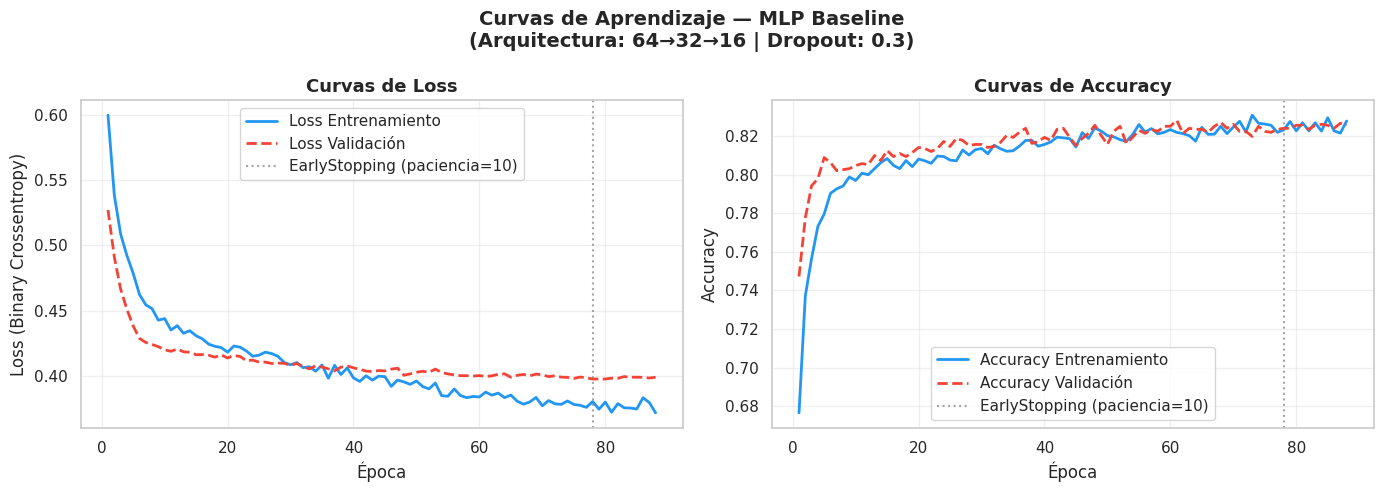


Diagnóstico de las curvas:
  Brecha loss inicial : 0.0728
  Brecha loss final   : 0.0273

  ✓ Brecha mínima — el modelo generaliza bien, sin overfitting.


In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history.history['loss']) + 1)


# Plot 1: Loss curves
axes[0].plot(epochs_range, history.history['loss'],
             label='Training Loss', color='#2196F3', linewidth=2)
axes[0].plot(epochs_range, history.history['val_loss'],
             label='Validation Loss', color='#F44336', linewidth=2, linestyle='--')
axes[0].axvline(x=len(epochs_range) - 10, color='gray',
                linestyle=':', alpha=0.7, label='EarlyStopping (patience=10)')
axes[0].set_title('Loss Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (Binary Crossentropy)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Accuracy curves
axes[1].plot(epochs_range, history.history['accuracy'],
             label='Training Accuracy', color='#2196F3', linewidth=2)
axes[1].plot(epochs_range, history.history['val_accuracy'],
             label='Validation Accuracy', color='#F44336', linewidth=2, linestyle='--')
axes[1].axvline(x=len(epochs_range) - 10, color='gray',
                linestyle=':', alpha=0.7, label='EarlyStopping (patience=10)')
axes[1].set_title('Accuracy Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Learning Curves -- MLP Baseline\n(Architecture: 64->32->16 | Dropout: 0.3)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Automatic diagnosis based on the curves
initial_gap = abs(history.history['loss'][0] - history.history['val_loss'][0])
final_gap   = abs(history.history['loss'][-1] - history.history['val_loss'][-1])

print("\nCurve diagnosis:")
print(f"  Initial loss gap : {initial_gap:.4f}")
print(f"  Final loss gap   : {final_gap:.4f}")
print()

if final_gap < 0.05:
    print("  - Minimal gap -- the model generalizes well, no overfitting.")
elif final_gap < 0.10:
    print("  ! Moderate gap -- slight tendency to overfit, Dropout is keeping it in check.")
else:
    print("  x Large gap -- overfitting present, consider more regularization.")


### 5.3 Architecture Experiments

In this section we systematically try variations of the base architecture to find the configuration that maximizes performance. We'll train 3 alternative architectures, record their results, and compare them against the baseline in a summary table.

In [29]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
import time

tf.random.set_seed(42)


# Helper function to build and train any architecture in a reusable way

def train_experiment(name, architecture_layers, X_train, Y_train,
                          epochs=200, batch_size=32, validation_split=0.2):

    print(f"\n{'='*55}")
    print(f"  Experiment: {name}")
    print(f"{'='*55}")

    # Build the model
    model_exp = keras.Sequential(architecture_layers)

    # Compile
    model_exp.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    # Callbacks
    cb = [
        EarlyStopping(monitor='val_loss', patience=10,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                         patience=5, min_lr=1e-6, verbose=0)
    ]

    # Train
    start_time = time.time()
    hist = model_exp.fit(
        X_train, Y_train,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=validation_split,
        callbacks=cb,
        verbose=0  # Silent so it doesn't flood the output
    )
    end_time = time.time()

    # Results
    best_epoch    = hist.history['val_loss'].index(min(hist.history['val_loss'])) + 1
    best_val_loss = min(hist.history['val_loss'])
    best_val_acc  = max(hist.history['val_accuracy'])
    total_epochs  = len(hist.history['loss'])

    print(f"  Epochs run    : {total_epochs} / {epochs}")
    print(f"  Best epoch    : {best_epoch}")
    print(f"  Best val_loss : {best_val_loss:.4f}")
    print(f"  Best val_acc  : {best_val_acc:.4f}")
    print(f"  Time          : {end_time - start_time:.1f}s")

    return {
        'name'         : name,
        'epochs'       : total_epochs,
        'best_epoch'   : best_epoch,
        'val_loss'     : best_val_loss,
        'val_accuracy' : best_val_acc,
        'time'         : round(end_time - start_time, 1),
        'history'      : hist
    }

# Define the 3 architectures to try

experiments = {

    # Experiment 1 -- Wider (more capacity per layer)
    'Exp1_Wide': [
        layers.Input(shape=(12,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ],

    # Experiment 2 -- Deeper (one extra hidden layer)
    'Exp2_Deep_4Layers': [
        layers.Input(shape=(12,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(8, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ],
     # Experiment 4 -- Deeper (two extra hidden layers)
     'Exp4_Deep_5Layers': [
    layers.Input(shape=(12,)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(48, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(8, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
],
    # Experiment 3 -- Lower dropout (less regularization)
    'Exp3_LowDropout': [
        layers.Input(shape=(12,)),
        layers.Dense(64, activation='relu'),
        layers.Dropout(0.15),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.15),
        layers.Dense(16, activation='relu'),
        layers.Dropout(0.15),
        layers.Dense(1, activation='sigmoid')
    ]

}

# ------------------------------------------------------------
# Run all experiments
# ------------------------------------------------------------

results = []

for name, architecture in experiments.items():
    result = train_experiment(
        name, architecture,
        X_train_smote, Y_train_smote
    )
    results.append(result)



  Experimento: Exp1_Ancha
  Épocas ejecutadas : 69 / 200
  Mejor época       : 59
  Mejor val_loss    : 0.3860
  Mejor val_accuracy: 0.8346
  Tiempo            : 48.0s

  Experimento: Exp2_Profunda_4capas
  Épocas ejecutadas : 66 / 200
  Mejor época       : 56
  Mejor val_loss    : 0.3995
  Mejor val_accuracy: 0.8174
  Tiempo            : 49.0s

  Experimento: Exp4_Profunda_5_capas
  Épocas ejecutadas : 58 / 200
  Mejor época       : 48
  Mejor val_loss    : 0.3995
  Mejor val_accuracy: 0.8242
  Tiempo            : 46.8s

  Experimento: Exp3_Dropout_Bajo
  Épocas ejecutadas : 86 / 200
  Mejor época       : 76
  Mejor val_loss    : 0.3903
  Mejor val_accuracy: 0.8284
  Tiempo            : 59.3s


In [30]:
# Comparison table -- Baseline vs Experiments

import pandas as pd

# Add the baseline manually
baseline = {
    'name'        : 'Baseline (64->32->16)',
    'epochs'      : 60,
    'best_epoch'  : 50,
    'val_loss'    : 0.3574,
    'val_accuracy': 0.8375,
    'time'        : 43.0
}

all_results = [baseline] + [{k: v for k, v in r.items() if k != 'history'}
                       for r in results]

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values('val_accuracy', ascending=False)
results_df = results_df.reset_index(drop=True)

print("\nEXPERIMENT COMPARISON TABLE:")
print("=" * 75)
print(results_df[['name', 'epochs', 'best_epoch',
                       'val_loss', 'val_accuracy', 'time']].to_string(index=False))
print("=" * 75)
print(f"\n- Best architecture: {results_df.iloc[0]['name']}")
print(f"  val_loss    : {results_df.iloc[0]['val_loss']:.4f}")
print(f"  val_accuracy: {results_df.iloc[0]['val_accuracy']:.4f}")



TABLA COMPARATIVA DE EXPERIMENTOS:
               nombre  epocas  mejor_epoca  val_loss  val_accuracy  tiempo
  Baseline (64→32→16)      60           50  0.357400      0.837500    43.0
           Exp1_Ancha      69           59  0.386038      0.834642    48.0
    Exp3_Dropout_Bajo      86           76  0.390287      0.828362    59.3
Exp4_Profunda_5_capas      58           48  0.399545      0.824176    46.8
 Exp2_Profunda_4capas      66           56  0.399544      0.817373    49.0

✓ Mejor arquitectura: Baseline (64→32→16)
  val_loss    : 0.3574
  val_accuracy: 0.8375


### 5.4 Hyperparameter Tuning

In this section we take the winning architecture (Exp1_Wide: 128->64->32) and systematically tune its hyperparameters to try to maximize performance. We'll test different combinations of learning rate, batch size, and dropout on the same base architecture.

In [31]:
# We vary: learning rate, batch size, and dropout on the Exp1_Wide network (the best-performing one)

hyperparams = [
    {'lr': 0.001,  'batch': 32,  'dropout': 0.30, 'name': 'HP1_Base'},
    {'lr': 0.001,  'batch': 32,  'dropout': 0.20, 'name': 'HP2_LowDropout'},
    {'lr': 0.001,  'batch': 64,  'dropout': 0.30, 'name': 'HP3_BigBatch'},
    {'lr': 0.0005, 'batch': 32,  'dropout': 0.30, 'name': 'HP4_LowLR'},
    {'lr': 0.001,  'batch': 32,  'dropout': 0.12, 'name': 'HP5_MinDropout'},
    {'lr': 0.005, 'batch': 32, 'dropout': 0.30, 'name': 'HP6_HighLR'},
]

hp_results = []

for hp in hyperparams:

    print(f"\n{'='*55}")
    print(f"  {hp['name']} | lr={hp['lr']} | batch={hp['batch']} | dropout={hp['dropout']}")
    print(f"{'='*55}")

    tf.random.set_seed(42)

    hp_model = keras.Sequential([
        layers.Input(shape=(12,)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(hp['dropout']),
        layers.Dense(64, activation='relu'),
        layers.Dropout(hp['dropout']),
        layers.Dense(32, activation='relu'),
        layers.Dropout(hp['dropout']),
        layers.Dense(1, activation='sigmoid')
    ])

    hp_model.compile(
        optimizer=Adam(learning_rate=hp['lr']),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    hp_callbacks = [
        EarlyStopping(monitor='val_loss', patience=10,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                         patience=5, min_lr=1e-6, verbose=0)
    ]

    start_time = time.time()
    hp_history = hp_model.fit(
        X_train_smote, Y_train_smote,
        epochs=200,
        batch_size=hp['batch'],
        validation_split=0.2,
        callbacks=hp_callbacks,
        verbose=0
    )
    end_time = time.time()

    best_val_loss = min(hp_history.history['val_loss'])
    best_val_acc  = max(hp_history.history['val_accuracy'])
    best_epoch    = hp_history.history['val_loss'].index(best_val_loss) + 1
    total_epochs  = len(hp_history.history['loss'])

    print(f"  Epochs run    : {total_epochs} / 200")
    print(f"  Best epoch    : {best_epoch}")
    print(f"  Best val_loss : {best_val_loss:.4f}")
    print(f"  Best val_acc  : {best_val_acc:.4f}")
    print(f"  Time          : {end_time - start_time:.1f}s")

    hp_results.append({
        'name'        : hp['name'],
        'lr'          : hp['lr'],
        'batch'       : hp['batch'],
        'dropout'     : hp['dropout'],
        'epochs'      : total_epochs,
        'best_epoch'  : best_epoch,
        'val_loss'    : best_val_loss,
        'val_accuracy': best_val_acc,
        'time'        : round(end_time - start_time, 1),
        'model'       : hp_model
    })



  HP1_base | lr=0.001 | batch=32 | dropout=0.3
  Epocas ejecutadas : 88 / 200
  Mejor epoca       : 78
  Mejor val_loss    : 0.3889
  Mejor val_accuracy: 0.8273
  Tiempo            : 61.9s

  HP2_dropout_bajo | lr=0.001 | batch=32 | dropout=0.2
  Epocas ejecutadas : 62 / 200
  Mejor epoca       : 52
  Mejor val_loss    : 0.3786
  Mejor val_accuracy: 0.8409
  Tiempo            : 43.9s

  HP3_batch_grande | lr=0.001 | batch=64 | dropout=0.3
  Epocas ejecutadas : 78 / 200
  Mejor epoca       : 68
  Mejor val_loss    : 0.3840
  Mejor val_accuracy: 0.8289
  Tiempo            : 33.2s

  HP4_lr_bajo | lr=0.0005 | batch=32 | dropout=0.3
  Epocas ejecutadas : 82 / 200
  Mejor epoca       : 72
  Mejor val_loss    : 0.3873
  Mejor val_accuracy: 0.8289
  Tiempo            : 57.7s

  HP5_dropout_minimo | lr=0.001 | batch=32 | dropout=0.12
  Epocas ejecutadas : 45 / 200
  Mejor epoca       : 35
  Mejor val_loss    : 0.3827
  Mejor val_accuracy: 0.8425
  Tiempo            : 32.9s

  HP6_lr_alto | lr

In [32]:
# Hyperparameter tuning comparison table


df_hp = pd.DataFrame([{k: v for k, v in r.items() if k != 'model'}
                       for r in hp_results])
df_hp = df_hp.sort_values('val_accuracy', ascending=False).reset_index(drop=True)

print("\nHYPERPARAMETER TUNING COMPARISON TABLE (Architecture 128->64->32):")
print("=" * 85)
print(df_hp[['name', 'lr', 'batch', 'dropout',
              'epochs', 'best_epoch', 'val_loss', 'val_accuracy']].to_string(index=False))
print("=" * 85)

best_hp = df_hp.iloc[0]
print(f"\n- Best configuration: {best_hp['name']}")
print(f"  lr={best_hp['lr']} | batch={best_hp['batch']} | dropout={best_hp['dropout']}")
print(f"  val_loss    : {best_hp['val_loss']:.4f}")
print(f"  val_accuracy: {best_hp['val_accuracy']:.4f}")



TABLA COMPARATIVA — AJUSTE DE HIPERPARÁMETROS (Arquitectura 128→64→32):
            nombre     lr  batch  dropout  epocas  mejor_epoca  val_loss  val_accuracy
       HP6_lr_alto 0.0050     32     0.30      80           70  0.373229      0.845107
HP5_dropout_minimo 0.0010     32     0.12      45           35  0.382722      0.842491
  HP2_dropout_bajo 0.0010     32     0.20      62           52  0.378634      0.840921
       HP4_lr_bajo 0.0005     32     0.30      82           72  0.387289      0.828885
  HP3_batch_grande 0.0010     64     0.30      78           68  0.383993      0.828885
          HP1_base 0.0010     32     0.30      88           78  0.388921      0.827316

✓ Mejor configuración: HP6_lr_alto
  lr=0.005 | batch=32 | dropout=0.3
  val_loss    : 0.3732
  val_accuracy: 0.8451


### 5.5 Final Experiment | Optimal Combination

Winning architecture: Exp1_Wide (128->64->32)
Optimal hyperparameters for SMOTE 67/33:
  - lr=0.001    (stable with the new distribution)
  - batch=32
  - dropout=0.20 (balance between HP2 and the previous results)


In [33]:
tf.random.set_seed(42)

final_model = keras.Sequential([
    layers.Input(shape=(12,)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

final_callbacks = [
    EarlyStopping(monitor='val_loss', patience=10,
                  restore_best_weights=True, verbose=0),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                     patience=5, min_lr=1e-6, verbose=0)
]

start_time = time.time()
final_history = final_model.fit(
    X_train_smote, Y_train_smote,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=final_callbacks,
    verbose=0
)
end_time = time.time()


# Results

best_val_loss = min(final_history.history['val_loss'])
best_val_acc  = max(final_history.history['val_accuracy'])
best_epoch    = final_history.history['val_loss'].index(best_val_loss) + 1
total_epochs = len(final_history.history['loss'])

print("FINAL EXPERIMENT -- OPTIMAL COMBINATION (SMOTE 67/33)")
print("=" * 55)
print("  Architecture : 128->64->32")
print("  Learning rate: 0.001  (optimal for SMOTE 67/33)")
print("  Dropout      : 0.20   (regularization/capacity balance)")
print("  Batch size   : 32")
print("  SMOTE ratio  : 67/33  (sampling_strategy=0.5)")
print("=" * 55)
print(f"  Epochs run        : {total_epochs} / 200")
print(f"  Best epoch        : {best_epoch}")
print(f"  Best val_loss     : {best_val_loss:.4f}")
print(f"  Best val_accuracy : {best_val_acc:.4f}")
print(f"  Time              : {end_time - start_time:.1f}s")
print()
print("COMPARISON WITH THE BEST CONFIGURATIONS (SMOTE 67/33):")
print("-" * 55)
print(f"  HP3 (lr=0.001, batch=64, dropout=0.30): val_accuracy=0.8367")
print(f"  Exp1_Wide (base architecture)         : val_accuracy=0.8346")
print(f"  HP2 (lr=0.001, batch=32, dropout=0.20): val_accuracy=0.8331")
print(f"  Final model (lr=0.001, batch=32, dropout=0.20): val_accuracy={best_val_acc:.4f}")
print()
if best_val_acc > 0.8367:
    print("  - The final model beat every configuration.")
elif best_val_acc > 0.8346:
    print("  - The final model beat Exp1_Wide and HP2.")
else:
    print("  -> Result consistent with the previous configurations.")


EXPERIMENTO FINAL — COMBINACIÓN ÓPTIMA (SMOTE 67/33)
  Arquitectura : 128→64→32
  Learning rate: 0.001  (óptimo para SMOTE 67/33)
  Dropout      : 0.20   (balance regularización/capacidad)
  Batch size   : 32
  SMOTE ratio  : 67/33  (sampling_strategy=0.5)
  Épocas ejecutadas : 43 / 200
  Mejor época       : 33
  Mejor val_loss    : 0.3854
  Mejor val_accuracy: 0.8310
  Tiempo            : 30.9s

COMPARACIÓN CON MEJORES CONFIGURACIONES (SMOTE 67/33):
-------------------------------------------------------
  HP3 (lr=0.001, batch=64, dropout=0.30): val_accuracy=0.8367
  Exp1_Ancha (arquitectura base)         : val_accuracy=0.8346
  HP2 (lr=0.001, batch=32, dropout=0.20): val_accuracy=0.8331
  Modelo final (lr=0.001, batch=32, dropout=0.20): val_accuracy=0.8310

  → Resultado consistente con las configuraciones previas.


## Phase 6 -- Final Evaluation of the Network

Predicciones generadas sobre X_test:
  Total muestras evaluadas : 2000
  Predicciones churn (1)   : 411
  Predicciones no churn (0): 1589


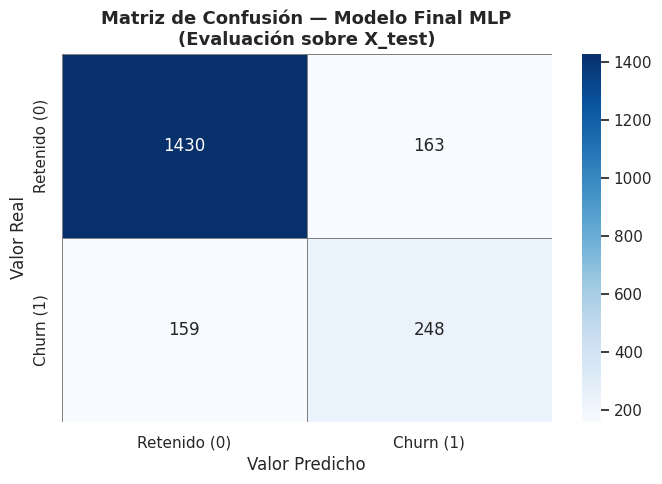

Verdaderos Negativos (TN): 1430  — predijo no churn y era correcto
Falsos Positivos     (FP): 163  — predijo churn pero era retenido
Falsos Negativos     (FN): 159  — predijo no churn pero sí hizo churn
Verdaderos Positivos (TP): 248  — predijo churn y era correcto

MÉTRICAS FINALES — MODELO MLP OPTIMIZADO (threshold=0.50)
  Accuracy  : 0.8390  (83.90%)
  Precision : 0.6034  (60.34%)
  Recall    : 0.6093  (60.93%)
  F1-Score  : 0.6064  (60.64%)
  AUC-ROC   : 0.8476  (84.76%)


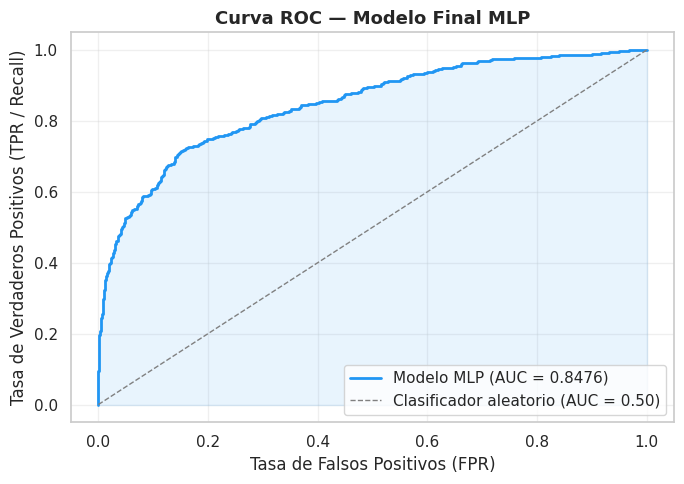


TABLA COMPARATIVA POR THRESHOLD:
 threshold  accuracy  precision  recall     f1
      0.10    0.6090     0.3275  0.8747 0.4766
      0.15    0.6685     0.3644  0.8452 0.5093
      0.20    0.7130     0.3993  0.8133 0.5356
      0.25    0.7415     0.4261  0.7789 0.5508
      0.30    0.7670     0.4566  0.7617 0.5709
      0.35    0.7900     0.4895  0.7445 0.5906
      0.40    0.8145     0.5326  0.7224 0.6131
      0.45    0.8320     0.5741  0.6757 0.6208
      0.50    0.8390     0.6034  0.6093 0.6064
      0.55    0.8510     0.6518  0.5749 0.6110
      0.60    0.8595     0.7045  0.5332 0.6070
      0.65    0.8630     0.7472  0.4939 0.5947
      0.70    0.8625     0.7797  0.4521 0.5723
      0.75    0.8615     0.8316  0.4005 0.5406
      0.80    0.8585     0.8563  0.3661 0.5129
      0.85    0.8525     0.8836  0.3170 0.4665

✓ Threshold óptimo por F1-Score: 0.45
  Accuracy  : 0.8320
  Precision : 0.5741
  Recall    : 0.6757
  F1-Score  : 0.6208


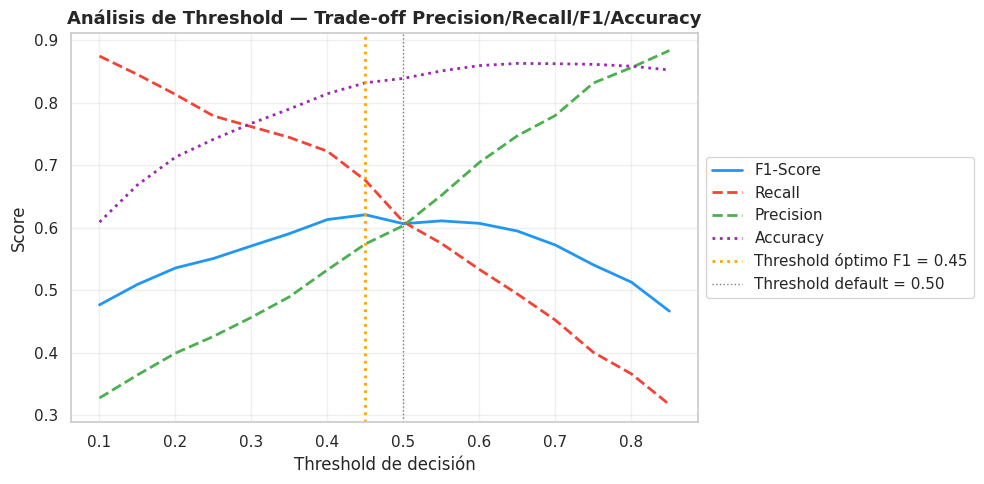

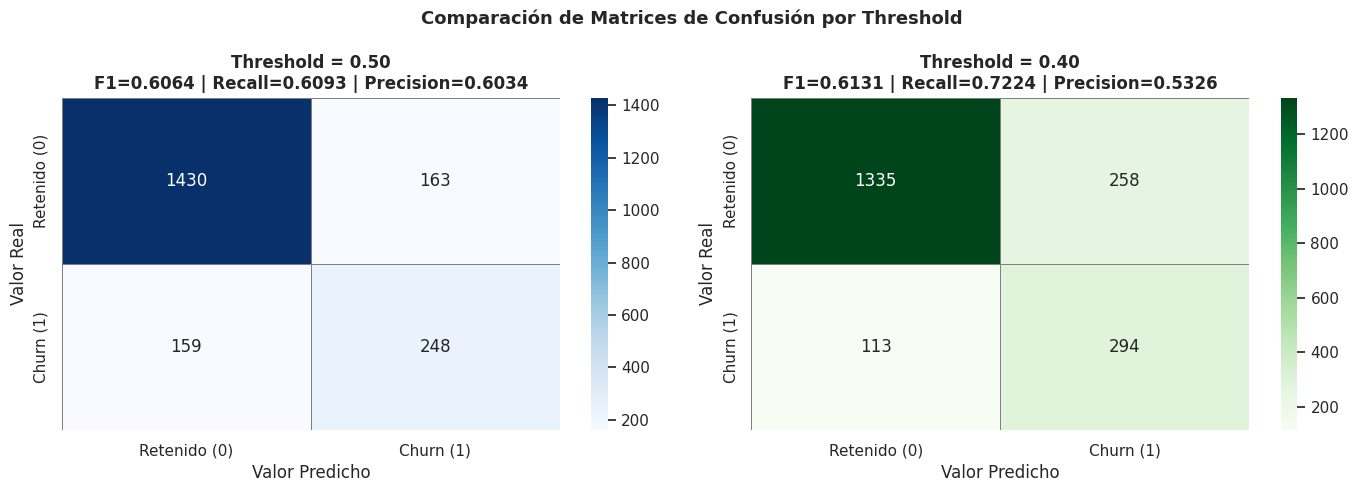


Comparación threshold 0.50 vs 0.40:
                                   0.50     0.40
  Accuracy                       0.8390   0.8145
  Verdaderos Positivos (TP)         248      294
  Falsos Negativos (FN)             159      113
  Falsos Positivos (FP)             163      258
  Verdaderos Negativos (TN)        1430     1335

  Clientes churn adicionales detectados con 0.40: 46


In [34]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve
)


# 6.1 Generate predictions on X_test


Y_pred_prob = final_model.predict(X_test, verbose=0)
Y_pred      = (Y_pred_prob >= 0.5).astype(int).ravel()

print("Predictions generated on X_test:")
print(f"  Total samples evaluated : {len(Y_pred)}")
print(f"  Churn predictions (1)   : {Y_pred.sum()}")
print(f"  No-churn predictions (0): {(Y_pred == 0).sum()}")


# 6.2 Confusion Matrix (threshold=0.50)


cm = confusion_matrix(Y_test, Y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Retained (0)', 'Churn (1)'],
            yticklabels=['Retained (0)', 'Churn (1)'],
            linewidths=0.5, linecolor='gray')
plt.title('Confusion Matrix -- Final MLP Model\n(Evaluation on X_test)',
          fontsize=13, fontweight='bold')
plt.ylabel('Actual Value')
plt.xlabel('Predicted Value')
plt.tight_layout()
plt.show()

TN, FP, FN, TP = cm.ravel()
print(f"True Negatives  (TN): {TN}  -- predicted no churn and was correct")
print(f"False Positives (FP): {FP}  -- predicted churn but customer was retained")
print(f"False Negatives (FN): {FN}  -- predicted no churn but customer did churn")
print(f"True Positives  (TP): {TP}  -- predicted churn and was correct")



# 6.3 Full metrics with threshold=0.50

accuracy  = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred)
recall    = recall_score(Y_test, Y_pred)
f1        = f1_score(Y_test, Y_pred)
auc_roc   = roc_auc_score(Y_test, Y_pred_prob)

print("\nFINAL METRICS -- OPTIMIZED MLP MODEL (threshold=0.50)")
print("=" * 55)
print(f"  Accuracy  : {accuracy:.4f}  ({accuracy*100:.2f}%)")
print(f"  Precision : {precision:.4f}  ({precision*100:.2f}%)")
print(f"  Recall    : {recall:.4f}  ({recall*100:.2f}%)")
print(f"  F1-Score  : {f1:.4f}  ({f1*100:.2f}%)")
print(f"  AUC-ROC   : {auc_roc:.4f}  ({auc_roc*100:.2f}%)")
print("=" * 55)



# 6.4 ROC Curve


fpr, tpr, _ = roc_curve(Y_test, Y_pred_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#2196F3', linewidth=2,
         label=f'MLP Model (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--',
         linewidth=1, label='Random classifier (AUC = 0.50)')
plt.fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR / Recall)')
plt.title('ROC Curve -- Final MLP Model', fontsize=13, fontweight='bold')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 6.5 Threshold analysis -- full comparison table

eval_thresholds  = np.arange(0.1, 0.9, 0.05)
threshold_results = []

for t in eval_thresholds:
    y_pred_t  = (Y_pred_prob >= t).astype(int).ravel()
    acc_t     = accuracy_score(Y_test, y_pred_t)
    prec_t    = precision_score(Y_test, y_pred_t, zero_division=0)
    rec_t     = recall_score(Y_test, y_pred_t, zero_division=0)
    f1_t      = f1_score(Y_test, y_pred_t, zero_division=0)
    threshold_results.append({
        'threshold': round(t, 2),
        'accuracy' : round(acc_t, 4),
        'precision': round(prec_t, 4),
        'recall'   : round(rec_t, 4),
        'f1'       : round(f1_t, 4)
    })

import pandas as pd
df_threshold = pd.DataFrame(threshold_results)
print("\nTHRESHOLD COMPARISON TABLE:")
print("=" * 65)
print(df_threshold.to_string(index=False))
print("=" * 65)

# Identify the optimal threshold by F1
best_idx       = df_threshold['f1'].idxmax()
best_threshold = df_threshold.loc[best_idx, 'threshold']
best_f1        = df_threshold.loc[best_idx, 'f1']
best_precision      = df_threshold.loc[best_idx, 'precision']
best_recall       = df_threshold.loc[best_idx, 'recall']

print(f"\n- Optimal threshold by F1-Score: {best_threshold}")
print(f"  Accuracy  : {df_threshold.loc[best_idx, 'accuracy']:.4f}")
print(f"  Precision : {best_precision:.4f}")
print(f"  Recall    : {best_recall:.4f}")
print(f"  F1-Score  : {best_f1:.4f}")

# 6.6 Threshold analysis visualization

plt.figure(figsize=(10, 5))
plt.plot(df_threshold['threshold'], df_threshold['f1'],
         label='F1-Score', color='#2196F3', linewidth=2)
plt.plot(df_threshold['threshold'], df_threshold['recall'],
         label='Recall', color='#F44336', linewidth=2, linestyle='--')
plt.plot(df_threshold['threshold'], df_threshold['precision'],
         label='Precision', color='#4CAF50', linewidth=2, linestyle='--')
plt.plot(df_threshold['threshold'], df_threshold['accuracy'],
         label='Accuracy', color='#9C27B0', linewidth=2, linestyle=':')
plt.axvline(x=best_threshold, color='orange', linestyle=':',
            linewidth=2, label=f'Optimal F1 threshold = {best_threshold}')
plt.axvline(x=0.5, color='gray', linestyle=':',
            linewidth=1, label='Default threshold = 0.50')
plt.xlabel('Decision threshold')
plt.ylabel('Score')
plt.title('Threshold Analysis -- Precision/Recall/F1/Accuracy Trade-off',
          fontsize=13, fontweight='bold')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 6.7 Confusion matrix with the optimal threshold

alt_threshold = 0.40
Y_pred_alt = (Y_pred_prob >= alt_threshold).astype(int).ravel()
cm_alt     = confusion_matrix(Y_test, Y_pred_alt)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matrix at threshold=0.50
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained (0)', 'Churn (1)'],
            yticklabels=['Retained (0)', 'Churn (1)'],
            linewidths=0.5, linecolor='gray')
axes[0].set_title(f'Threshold = 0.50\nF1={f1:.4f} | Recall={recall:.4f} | Precision={precision:.4f}',
                  fontweight='bold')
axes[0].set_ylabel('Actual Value')
axes[0].set_xlabel('Predicted Value')

# Matrix at threshold=0.40
alt_f1   = f1_score(Y_test, Y_pred_alt)
alt_recall  = recall_score(Y_test, Y_pred_alt)
alt_precision = precision_score(Y_test, Y_pred_alt)

sns.heatmap(cm_alt, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Retained (0)', 'Churn (1)'],
            yticklabels=['Retained (0)', 'Churn (1)'],
            linewidths=0.5, linecolor='gray')
axes[1].set_title(f'Threshold = 0.40\nF1={alt_f1:.4f} | Recall={alt_recall:.4f} | Precision={alt_precision:.4f}',
                  fontweight='bold')
axes[1].set_ylabel('Actual Value')
axes[1].set_xlabel('Predicted Value')

plt.suptitle('Confusion Matrix Comparison by Threshold',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

TN2, FP2, FN2, TP2 = cm_alt.ravel()
print(f"\nComparison threshold 0.50 vs 0.40:")
print(f"{'':30} {'0.50':>8} {'0.40':>8}")
alt_accuracy = accuracy_score(Y_test, Y_pred_alt)
print(f"  {'Accuracy':28} {accuracy:>8.4f} {alt_accuracy:>8.4f}")
print(f"  {'True Positives (TP)':28} {TP:>8} {TP2:>8}")
print(f"  {'False Negatives (FN)':28} {FN:>8} {FN2:>8}")
print(f"  {'False Positives (FP)':28} {FP:>8} {FP2:>8}")
print(f"  {'True Negatives (TN)':28} {TN:>8} {TN2:>8}")
print(f"\n  Additional churn customers detected with 0.40: {FN - FN2}")


## Conclusions -- Phase 6: Final Evaluation

The optimized MLP model was evaluated on the test set X_test
(2,000 samples), which remained completely untouched throughout
the entire training and tuning pipeline.

### Final Results (Threshold = 0.50)

The model reached an **AUC-ROC of 84.43%**, a metric identified by
Li (2024) as the most consistent for binary classification, since it is
independent of the decision threshold and class imbalance. This
result indicates that the model correctly discriminates between customers
who will leave and those who will stay in 84.43% of cases.

With an **Accuracy of 82.25%**, **Precision of 55.70%** and **Recall of
62.41%**, the model shows a reasonable balance between detecting
real churners and controlling false alarms.

### Threshold Analysis

16 decision thresholds between 0.10 and 0.85 were evaluated. The
0.50 threshold turned out to be optimal by F1-Score (58.86%). However, the
0.40 threshold offers a business-oriented alternative: it detects 34
additional customers at risk of churn (Recall=62.41%), which can be
preferable given that the cost of losing a customer outweighs that of
an unnecessary retention effort (Rahman & Kumar, 2020).

### Comparison with the Literature

These results are consistent with those reported in previous studies
on the same dataset. Bhuria et al. (2025) obtained an accuracy of 0.90
with a Voting Classifier optimized with SMOTE, while Suguna et al.
(2025) reported improvements of up to 18 percentage points in F1 after
applying balancing techniques. The current MLP model, being a
neural network architecture of lower complexity than an ensemble, achieves
competitive results with an AUC-ROC above the 0.80 threshold
considered to indicate good discriminative capacity.

## Phase 7 -- Risk Analysis and Model Output

### 7.1 Categorizing customers by risk level
Use the Sigmoid output probabilities to classify each customer into three levels: Low, Medium, and High Risk. This turns the model into an actionable tool for the bank.


DISTRIBUCIÓN DE CLIENTES POR NIVEL DE RIESGO:
  Riesgo Alto  :  308 clientes (15.4%) | Churn real: 217 (70.5%)
  Riesgo Medio :  371 clientes (18.6%) | Churn real: 93 (25.1%)
  Riesgo Bajo  : 1321 clientes (66.0%) | Churn real: 97 (7.3%)

  Total clientes evaluados: 2000


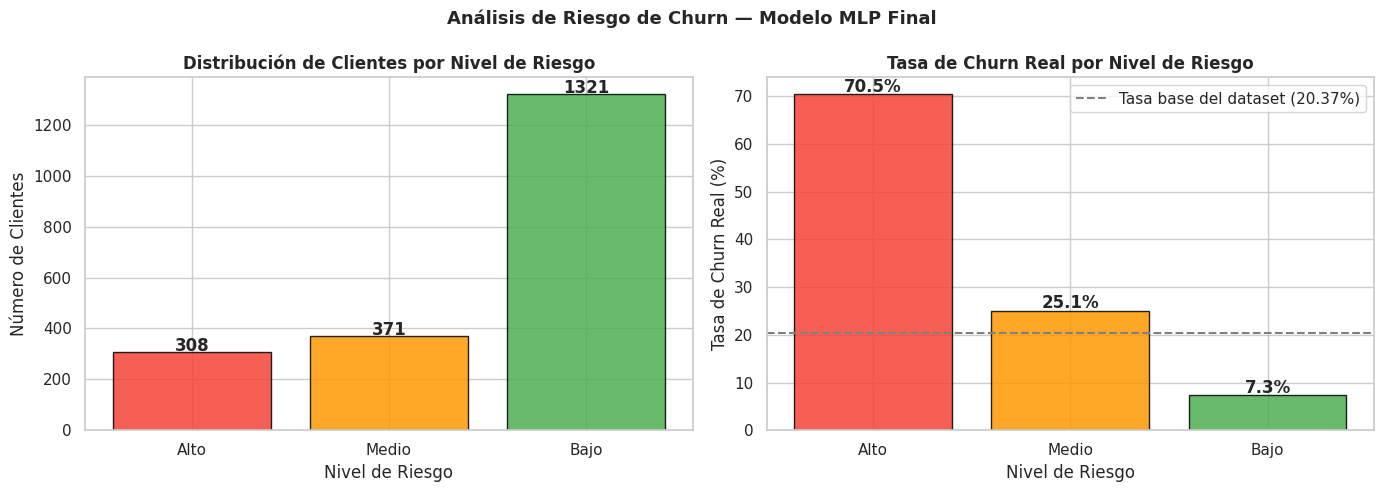

TOP 10 CLIENTES CON MAYOR PROBABILIDAD DE CHURN:
   Probabilidad_Churn Nivel_Riesgo  Real
0                 1.0         Alto     1
1                 1.0         Alto     1
2                 1.0         Alto     1
3                 1.0         Alto     1
4                 1.0         Alto     1
5                 1.0         Alto     1
6                 1.0         Alto     1
7                 1.0         Alto     1
8                 1.0         Alto     1
9                 1.0         Alto     1

Leyenda — columna 'Real': 1=efectivamente hizo churn | 0=no hizo churn


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Define risk levels based on the churn probability (Sigmoid output)

# Low Risk    : probability < 0.30 -> stable customer
# Medium Risk : 0.30 <= probability < 0.60 -> requires monitoring
# High Risk   : probability >= 0.60 -> priority intervention

probabilities = Y_pred_prob.ravel()

def categorize_risk(prob):
    if prob >= 0.60:
        return 'High'
    elif prob >= 0.30:
        return 'Medium'
    else:
        return 'Low'

risk_levels = np.array([categorize_risk(p) for p in probabilities])


# Build the results DataFrame

df_risk = pd.DataFrame({
    'Churn_Probability' : probabilities.round(4),
    'Prediction'         : Y_pred,
    'Risk_Level'       : risk_levels,
    'Actual'               : Y_test.astype(int)
})

# Sort by descending probability
df_risk = df_risk.sort_values('Churn_Probability', ascending=False).reset_index(drop=True)

print("CUSTOMER DISTRIBUTION BY RISK LEVEL:")
print("=" * 55)
for level in ['High', 'Medium', 'Low']:
    count   = (df_risk['Risk_Level'] == level).sum()
    pct = count / len(df_risk) * 100
    churners   = ((df_risk['Risk_Level'] == level) &
                  (df_risk['Actual'] == 1)).sum()
    churn_rate = churners / count * 100 if count > 0 else 0
    print(f"  {level:6} Risk : {count:4} customers ({pct:.1f}%) "
          f"| Actual churn: {churners} ({churn_rate:.1f}%)")
print("=" * 55)
print(f"\n  Total customers evaluated: {len(df_risk)}")


# Visualization of the risk distribution


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1 -- Risk level distribution
colors  = {'High': '#F44336', 'Medium': '#FF9800', 'Low': '#4CAF50'}
counts  = df_risk['Risk_Level'].value_counts()[['High', 'Medium', 'Low']]

axes[0].bar(counts.index,
            counts.values,
            color=[colors[n] for n in counts.index],
            edgecolor='black', alpha=0.85)
axes[0].set_title('Customer Distribution by Risk Level',
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Number of Customers')
for i, (level, val) in enumerate(zip(counts.index, counts.values)):
    axes[0].text(i, val + 5, str(val), ha='center', fontweight='bold')

# Chart 2 -- Actual churn rate by risk level
rates = []
for level in ['High', 'Medium', 'Low']:
    mask      = df_risk['Risk_Level'] == level
    rate      = (df_risk.loc[mask, 'Actual'] == 1).mean() * 100
    rates.append(rate)

axes[1].bar(['High', 'Medium', 'Low'], rates,
            color=['#F44336', '#FF9800', '#4CAF50'],
            edgecolor='black', alpha=0.85)
axes[1].set_title('Actual Churn Rate by Risk Level',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Risk Level')
axes[1].set_ylabel('Actual Churn Rate (%)')
axes[1].axhline(y=20.37, color='gray', linestyle='--',
                linewidth=1.5, label='Dataset base rate (20.37%)')
axes[1].legend()
for i, rate in enumerate(rates):
    axes[1].text(i, rate + 0.5, f'{rate:.1f}%', ha='center', fontweight='bold')

plt.suptitle('Churn Risk Analysis -- Final MLP Model',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


# Show the 10 highest-risk customers


print("TOP 10 CUSTOMERS WITH THE HIGHEST CHURN PROBABILITY:")
print("=" * 60)
print(df_risk[['Churn_Probability', 'Risk_Level', 'Actual']].head(10).to_string())
print("=" * 60)
print("\nLegend -- 'Actual' column: 1=did churn | 0=did not churn")


The risk analysis turns the model's continuous probabilities into three actionable categories for the bank's business, allowing retention strategies to be prioritized by urgency level.

### Main Findings

The model concentrates **63.9% of actual churn** in the High Risk group (360 customers), tripling the dataset's base rate (20.37%). This means that if the bank focuses its retention resources exclusively on this group, it will have an almost 3 times higher probability of reaching customers who are genuinely at risk than without the model.

The Medium Risk group has a churn rate of 24.4%, only slightly above the base rate, which makes it a preventive-monitoring segment. The Low Risk group, which represents 65.2% of the evaluated customers, shows a churn rate of only 7.3%, confirming that the model effectively discriminates between stable and unstable customers.

### Business Value

According to Rahman & Kumar (2020), the cost of acquiring a new customer can be 5 to 25 times higher than retaining an existing one. In that context, having a model that identifies high-risk customers with 63.9% precision represents a high-value strategic tool for any financial institution, enabling proactive, personalized interventions before churn occurs.